In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

print("Подключено")

Matplotlib is building the font cache; this may take a moment.


Подключено


In [2]:
query = """
select
    customer_unique_id,
    order_date
from marts.fact_orders f
join staging.customers c on f.customer_id = c.customer_id
where f.order_status = 'delivered'
  and f.order_date is not null
"""

df = pd.read_sql(query, engine)
print(df.shape)
df.head()

(96478, 2)


,customer_unique_id,order_date
0,7c396fd4830fd04220f754e42b4e5bff,2017-10-02
1,39382392765b6dc74812866ee5ee92a7,2017-01-23
2,e2dfa3127fedbbca9707b36304996dab,2018-07-25
3,6e26bbeaa107ec34112c64e1ee31c0f5,2018-01-02
4,d0ff1a7468fcc46b8fc658ab35d2a12c,2017-11-21


In [3]:
df["order_date"] = pd.to_datetime(df["order_date"])

# месяц первого заказа = когорта клиента
df["cohort_month"] = (
    df.groupby("customer_unique_id")["order_date"]
      .transform("min")
      .dt.to_period("M")
)

# месяц текущего заказа
df["order_month"] = df["order_date"].dt.to_period("M")

# номер месяца внутри когорты (0 = месяц первого заказа)
df["cohort_index"] = (
    (df["order_month"].dt.year - df["cohort_month"].dt.year) * 12
    + (df["order_month"].dt.month - df["cohort_month"].dt.month)
)

df.head()

,customer_unique_id,order_date,cohort_month,order_month,cohort_index
0,7c396fd4830fd04220f754e42b4e5bff,2017-10-02,2017-09,2017-10,1
1,39382392765b6dc74812866ee5ee92a7,2017-01-23,2017-01,2017-01,0
2,e2dfa3127fedbbca9707b36304996dab,2018-07-25,2018-07,2018-07,0
3,6e26bbeaa107ec34112c64e1ee31c0f5,2018-01-02,2017-07,2018-01,6
4,d0ff1a7468fcc46b8fc658ab35d2a12c,2017-11-21,2017-11,2017-11,0


In [4]:
# сколько уникальных клиентов в каждой когорте по каждому месяцу жизни
cohort_data = (
    df.groupby(["cohort_month", "cohort_index"])["customer_unique_id"]
      .nunique()
      .reset_index(name="customers")
)

# размер когорты = число клиентов при index = 0
cohort_sizes = cohort_data[cohort_data["cohort_index"] == 0].set_index("cohort_month")["customers"]

# делим на размер когорты → получаем retention
cohort_data["retention"] = (
    cohort_data["customers"]
    / cohort_data["cohort_month"].map(cohort_sizes)
) * 100

cohort_data.head()

,cohort_month,cohort_index,customers,retention
0,2016-09,0,1,100.000000
1,2016-10,0,262,100.000000
2,2016-10,6,1,0.381679
3,2016-10,9,1,0.381679
4,2016-10,11,1,0.381679


In [5]:
cohort_pivot = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="retention"
)

cohort_pivot.round(1).head()

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.4,NaN,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,0.8,0.8
2016-12,100.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7,0.4,0.1,0.1,0.3,0.4,0.1,NaN
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1,0.2,0.1,0.1,0.1,0.2,NaN,NaN


FileNotFoundError: [Errno 2] No such file or directory: '/Users/dmitry.burmistenko/VSCode/ecommerce-analytics/ecommerce-analytics/dashboards/screenshots/cohorts.png'

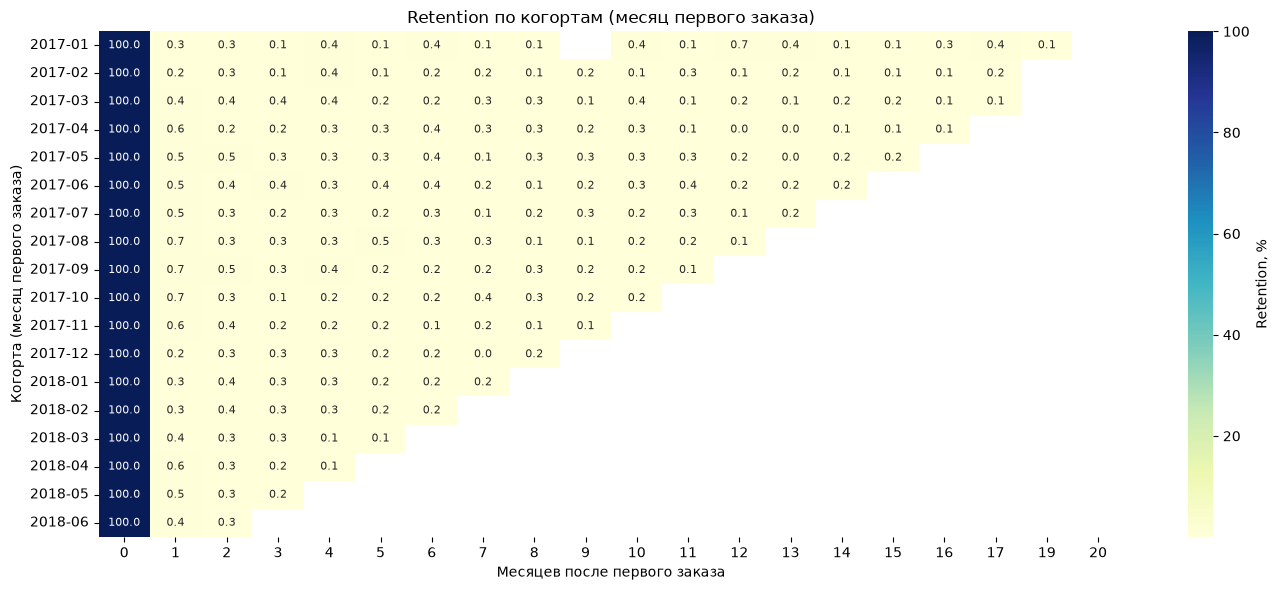

In [9]:
# ограничиваем когорты 2017 года, где данных достаточно
plot_data = cohort_pivot.loc["2017-01":"2018-06"]

plt.figure(figsize=(14, 6))
sns.heatmap(
    plot_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Retention, %"},
    annot_kws={"size": 8},
)
plt.title("Retention по когортам (месяц первого заказа)")
plt.xlabel("Месяцев после первого заказа")
plt.ylabel("Когорта (месяц первого заказа)")
plt.tight_layout()
plt.savefig("/Users/dmitry.burmistenko/VSCode/ecommerce-analytics/ecommerce-analytics/dashboards/screenshots/cohorts.png", dpi=120)
plt.show()